In [ ]:
import pandas as pd
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller


df = pd.read_csv("spiff_data-2.csv")

df = df.drop([35, 1193, 2835, 3429, 4117], errors='ignore')
df_nooutlier = df.drop([35, 1193, 2835, 3429, 4117], errors='ignore')

# Clean the data
df_small = df_nooutlier.dropna().reset_index(drop=True)
df_small = df_small.drop(columns=['index', 'Unnamed: 0', "day"], errors='ignore')

# Log transform
df_small_log = df_small.copy()
columns = ["gurkor", "guitars", "slingshots", "stocks", "sugar", "water", "tranquillity"]
df_small_log[columns] = np.log(df_small[columns])

# First, compute first differences (log returns)
df_small_log_dif1 = df_small_log.copy()
for col in columns:
    df_small_log_dif1[col] = (df_small_log_dif1[col]).diff()
df_small_log_dif1 = df_small_log_dif1.dropna()

"""
#tested more differencing options, but 1 is sufficient for stationarity

# Then, compute second differences (difference of first differences)
df_small_log_dif2 = df_small_log_dif1.copy()
for col in columns:
    df_small_log_dif2[col] = (df_small_log_dif2[col]).diff()
df_small_log_dif2 = df_small_log_dif2.dropna()


df_small_log_dif3 = df_small_log_dif2.copy()
for col in columns:
    df_small_log_dif3[col] = (df_small_log_dif3[col]).diff()
df_small_log_dif3 = df_small_log_dif3.dropna()
"""

# ADF test on log levels, checks for stationarity
for column in columns:
    result = adfuller(df_small_log_dif1[column].dropna())
    print(f'\nADF Test for column: {column}')
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    print('Critical Values:', result[4])


ADF Test for column: gurkor
ADF Statistic: -51.53165054515404
p-value: 0.0
Critical Values: {'1%': np.float64(-3.4316857963299587), '5%': np.float64(-2.8621302748271673), '10%': np.float64(-2.5670842044710875)}

ADF Test for column: guitars
ADF Statistic: -13.740011248455415
p-value: 1.098892991587664e-25
Critical Values: {'1%': np.float64(-3.4316923773763293), '5%': np.float64(-2.862133182268464), '10%': np.float64(-2.5670857522206294)}

ADF Test for column: slingshots
ADF Statistic: -18.68872200075503
p-value: 2.039912202267172e-30
Critical Values: {'1%': np.float64(-3.431689078767376), '5%': np.float64(-2.862131724976406), '10%': np.float64(-2.567084976444515)}

ADF Test for column: stocks
ADF Statistic: -70.47975501990226
p-value: 0.0
Critical Values: {'1%': np.float64(-3.4316855235197457), '5%': np.float64(-2.86213015430217), '10%': np.float64(-2.5670841403107416)}

ADF Test for column: sugar
ADF Statistic: -53.107049792247125
p-value: 0.0
Critical Values: {'1%': np.float64(-3.43

In [2]:
from statsmodels.tsa.stattools import bds

columns = ["gurkor", "guitars", "slingshots", "stocks", "sugar", "water", "tranquillity"]

#BDS test for non linearity, significant result indicates non linear relationship
bds_results = []

for col in columns:
    log_returns = df_small_log_dif1[col].values
    test_result = bds(log_returns, max_dim=2)
    bds_results.append({
        'Column': col,
        'BDS Statistic': test_result[0],
        'p-value': test_result[1]
    })

bds_results_df = pd.DataFrame(bds_results)
print(bds_results_df)

#all assets indicate low p-values except stocks, non linear model should be necessary

         Column        BDS Statistic                 p-value
0        gurkor    6.213099155339716   5.194964427980635e-10
1       guitars   13.169034322311168  1.3227874482164004e-39
2    slingshots   17.827303653397294   4.338458706129235e-71
3        stocks  -1.3532590788251018     0.17597287729924305
4         sugar    6.625667300715851  3.4568296453557045e-11
5         water    8.856931725229465   8.224687318737443e-19
6  tranquillity   10.941204059026042   7.322094405816191e-28


In [3]:
from skforecast.model_selection import backtesting_forecaster_multiseries, TimeSeriesFold
from skforecast.direct import ForecasterDirectMultiVariate
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd

#we will first forecast water using gurkor
#these are derived from the autocorrelation plots, 
#essentially we are looking for some significant lag relationship between the series that we want to leverage
series = ['water', 'gurkor']
lags_dict = {'water': [1], 'gurkor': [3, 4]}
data = df_small_log_dif1[series].dropna().reset_index(drop=True)

# Set horizon
horizon = 200

# setting our prefered forecaster, any scikit regressor works fine randomforest better result and xgbregressor is quicker worse result.
# the function will create a feature matrix, the Xtrain which will train our model.
# The matrix will contain the original values of water with some lagged columns that are relevant.
# From the autocorrelation plots we notice that water correlates with itself at lag 1 and we have some correlation between gurkor at lag 3,4.


# there is a sepearet model trained for each 200 horizons, first model trains to predict next step, second model trains to predict 2 steps ahead etc.
# note here that this is a direct multi step forecasting, not recursive. Meaning that we do not use previously predicted steps as input.
forecaster_water = ForecasterDirectMultiVariate(
        estimator=RandomForestRegressor(n_estimators=100, random_state=42),
        level='water',
        lags=lags_dict,
        steps=horizon,
        transformer_series=None,
    )
# Define series as a DataFrame
series_df = data[['water', 'gurkor']]

# Cross-validation, predict 200 steps ahead for each fold which are used to derive the CI bounds for each point
# using refit false, we fit the 200 models on the first fold, then reuse it on the other. If True, we would get 200*10 model fits, takes some time. 
# its also possible to use refit with n, which fixes the amount of refits
cv = TimeSeriesFold(
    steps=horizon,
    initial_train_size=2900,
    refit=False,
    fixed_train_size=False,
    gap=0,
    allow_incomplete_fold=True
)

# Backtesting will derive the CI bounds for each predicted point in a 200 point horizon using bootstrapping
# predictions_dict will contain the predicted points with the lower/upper bound for that point
metrics, predictions_dict = backtesting_forecaster_multiseries(
    forecaster=forecaster_water,
    series=series_df,
    cv=cv,
    metric='mean_squared_error',
    n_jobs='auto',
    verbose=True,
    show_progress=True,
    interval = [2.5,97.5],
    n_boot = 1000, #bootstrapping iterations
    use_in_sample_residuals = True
    )

####### summing the bounds for each 200 intervall predictions and taking the average #######

bounds = predictions_dict[['lower_bound', 'upper_bound']]  # shape: (2000, 2)

# Reshape to (10, 200, 2) to group by fold and prediction point
bounds_reshaped = bounds.values.reshape(10, 200, 2)  # 10 folds, 200 steps, 2 bounds

# Average across folds (axis=0)
avg_bounds = np.mean(bounds_reshaped, axis=0)  # shape: (200, 2)

# avg_bounds shape: (200, 2)
avg_bounds_df = pd.DataFrame(avg_bounds, columns=['lower_bound', 'upper_bound'])


####### deriving the predictions for the next 200 datapoints on water #######
horizon=200
lags_dict = {
    'water': [1],      #water lag 1
    'gurkor': [3, 4],     # gurkor lag 3,4
}

X_train, y_train = forecaster_water.create_train_X_y(data)
forecaster_water.fit(series=data)

X_predict = forecaster_water.create_predict_X(200)
predictions_water = forecaster_water.predict()


/home/df/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Information of folds
--------------------
Number of observations used for initial training: 2900
Number of observations used for backtesting: 2000
    Number of folds: 10
    Number skipped folds: 0 
    Number of steps per fold: 200
    Number of steps to exclude between last observed data (last window) and predictions (gap): 0

Fold: 0
    Training:   0 -- 2899  (n=2900)
    Validation: 2900 -- 3099  (n=200)
Fold: 1
    Training:   No training in this fold
    Validation: 3100 -- 3299  (n=200)
Fold: 2
    Training:   No training in this fold
    Validation: 3300 -- 3499  (n=200)
Fold: 3
    Training:   No training in this fold
    Validation: 3500 -- 3699  (n=200)
Fold: 4
    Training:   No training in this fold
    Validation: 3700 -- 3899  (n=200)
Fold: 5
    Training:   No training in this fold
    Validation: 3900 -- 4099  (n=200)
Fold: 6
    Training:   No training in this fold
    Validation: 4100 -- 4299  (n=200)
Fold: 7
    Training:   No training in this fold
    Validation:

100%|██████████| 10/10 [00:01<00:00,  5.63it/s]


In [4]:
X_train

,water_lag_1,gurkor_lag_3,gurkor_lag_4
203,0.001072,-0.003396,0.005666
204,0.001392,-0.001986,-0.003396
205,-0.000428,-0.005125,-0.001986
206,0.000000,0.003420,-0.005125
207,0.003206,0.001137,0.003420
...,...,...,...
4895,-0.007467,-0.000701,0.002105
4896,0.001625,-0.003748,-0.000701
4897,0.003242,-0.004116,-0.003748
4898,-0.001338,-0.001887,-0.004116


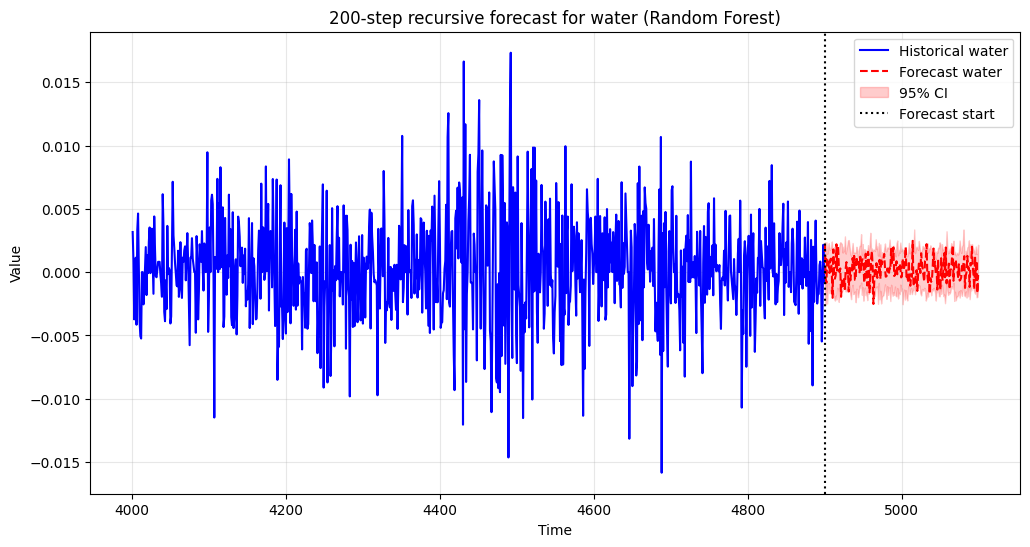

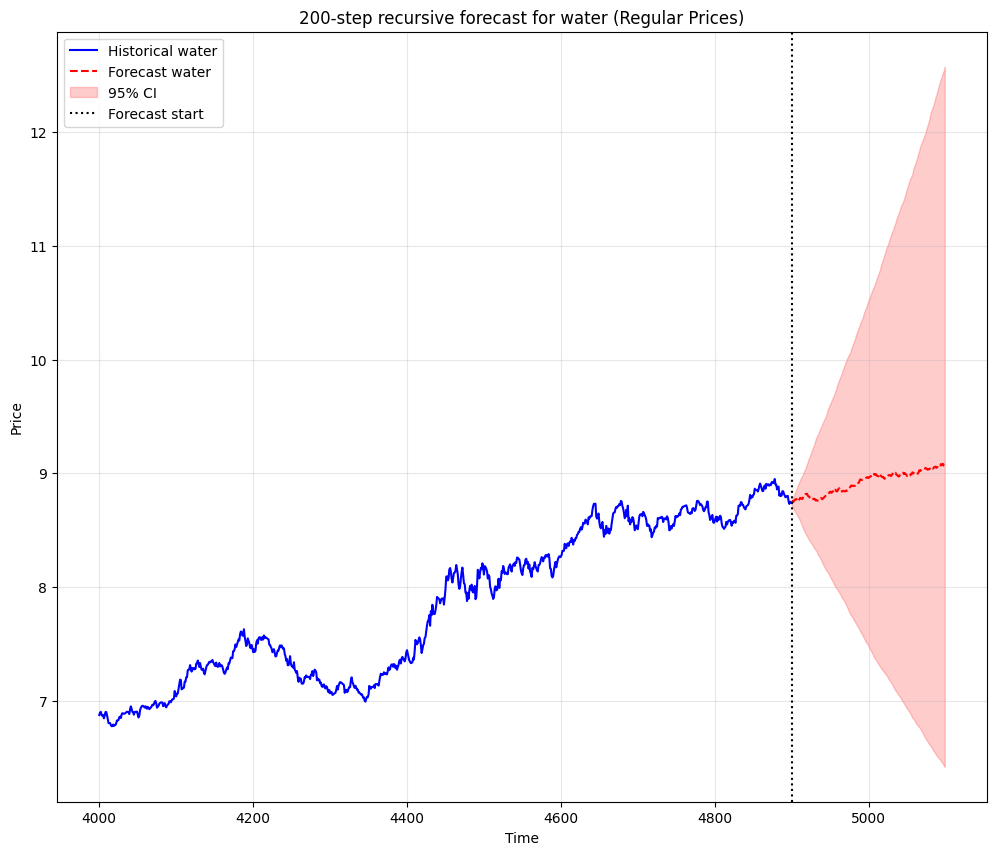

In [5]:
########### log returns plot ############

horizon = 200
forecast_index = range(len(df_small_log_dif1), len(df_small_log_dif1) + horizon)

plt.figure(figsize=(12, 6))

# Historical
plt.plot(df_small_log_dif1.index[4000:], df_small_log_dif1['water'][4000:], label='Historical water', color='blue')

# Forecast
plt.plot(forecast_index, predictions_water["pred"],
         label='Forecast water', color='red', linestyle='--')

# Confidence Interval
plt.fill_between(forecast_index,
                 avg_bounds_df['lower_bound'],
                 avg_bounds_df['upper_bound'],
                 color='red', alpha=0.2, label='95% CI')

plt.axvline(x=df_small_log_dif1.index[-1], color='black', linestyle=':', label='Forecast start')
plt.title('200-step recursive forecast for water (Random Forest)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


########### original price plot ############
water_log_prices = df_small_log_dif1["water"]
water_prices = df_small["water"]
last_water_log_price = df_small_log["water"].iloc[-1]


forecast_water_log_prices = last_water_log_price + np.cumsum(predictions_water["pred"])
forecast_water= np.exp(forecast_water_log_prices)


# Convert avg_bounds_df (log-return bounds) to log-price bounds
forecast_water_log_lower = last_water_log_price + np.cumsum(avg_bounds_df['lower_bound'])
forecast_water_log_upper = last_water_log_price + np.cumsum(avg_bounds_df['upper_bound'])

# Convert log-price bounds to actual price bounds
forecast_water_lower = np.exp(forecast_water_log_lower)
forecast_water_upper = np.exp(forecast_water_log_upper)

# Plot
plt.figure(figsize=(12, 10))

# Historical
plt.plot(df_small.index[4000:], water_prices[4000:], label='Historical water', color='blue')

# Forecast
plt.plot(forecast_index, forecast_water,
         label='Forecast water', color='red', linestyle='--')

# Confidence Interval
plt.fill_between(forecast_index,
                 forecast_water_lower,
                 forecast_water_upper,
                 color='red', alpha=0.2, label='95% CI')

plt.axvline(x=df_small.index[-1], color='black', linestyle=':', label='Forecast start')
plt.title('200-step recursive forecast for water (Regular Prices)')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
